# Identidades de los frutos propios y grupos de evaluación

**Manzana roja, banano y limón · 51 fotografías propias**

El objetivo es registrar qué vistas corresponden al mismo fruto y preparar grupos
que eviten repartir sus fotografías entre entrenamiento y evaluación. Las
identidades se proponen por inspección de marcas, forma, pedúnculo y secuencia.
La certeza visual es cualitativa, no una probabilidad calibrada.

El usuario confirmó que las manzanas del 16 y del 23 de noviembre eran frutos
diferentes. Las correspondencias inciertas dentro de una fecha siguen vinculadas.
Los identificadores y grupos son metadatos; no cambian calidad ni máscaras y no
se utilizan como características predictoras.

El usuario confirmó además que IMG_6120 e IMG_6121 muestran la misma manzana: EQ_MANZANA_07.

## 1. Cargar y verificar la anotación de identidad

Cada aparición de un fruto es una ocurrencia. Una fotografía de varios frutos puede
tener varias ocurrencias, sin convertirse por ello en una muestra de entrenamiento
completa. Los identificadores son perfiles propuestos, no un censo físico verificado.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display,clear_output

candidatas=[Path.cwd(),*Path.cwd().parents,Path.cwd()/'proyecto_estado_frutas']
PROYECTO=next(p for p in candidatas if (p/'config/alcance_actual.json').is_file())
if str(PROYECTO) not in sys.path:sys.path.insert(0,str(PROYECTO))
from src.data.identidad_frutos import cargar_identidades,exportar_identidades,crear_evidencia,guardar_identidad_individual
from src.data.exportar_base_v2 import exportar

catalogo,ocurrencias,fotos=exportar_identidades(PROYECTO)
crear_evidencia(PROYECTO)
print('Fotografías:',len(fotos),'| Perfiles propuestos:',len(catalogo),'| Ocurrencias/regiones:',len(ocurrencias))
display(fotos.groupby(['fruta','estado_identidad']).size().rename('fotografias').reset_index())
display(catalogo[['id_fruto','fruta','fotografias_individuales','grupo_evaluacion_seguro']])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\felipe\\APOIII\\proyecto_estado_frutas\\data\\processed\\drive_20261124\\miniaturas\\drive_1h30Crjf8nJ8DvFZerO_KyRPtdJ2obuHt.jpg'

## 2. Ejemplos de vistas repetidas y referencias de grupo

Las marcas del extremo vinculan las dos vistas del banano 01. La forma oval y las
dos puntas vinculan las vistas del limón 01. El pedúnculo curvado distingue las
vistas de la manzana 03. Las fotos de grupo proporcionan referencias de frutos
presentes simultáneamente. Un signo de interrogación indica una asociación menos segura.

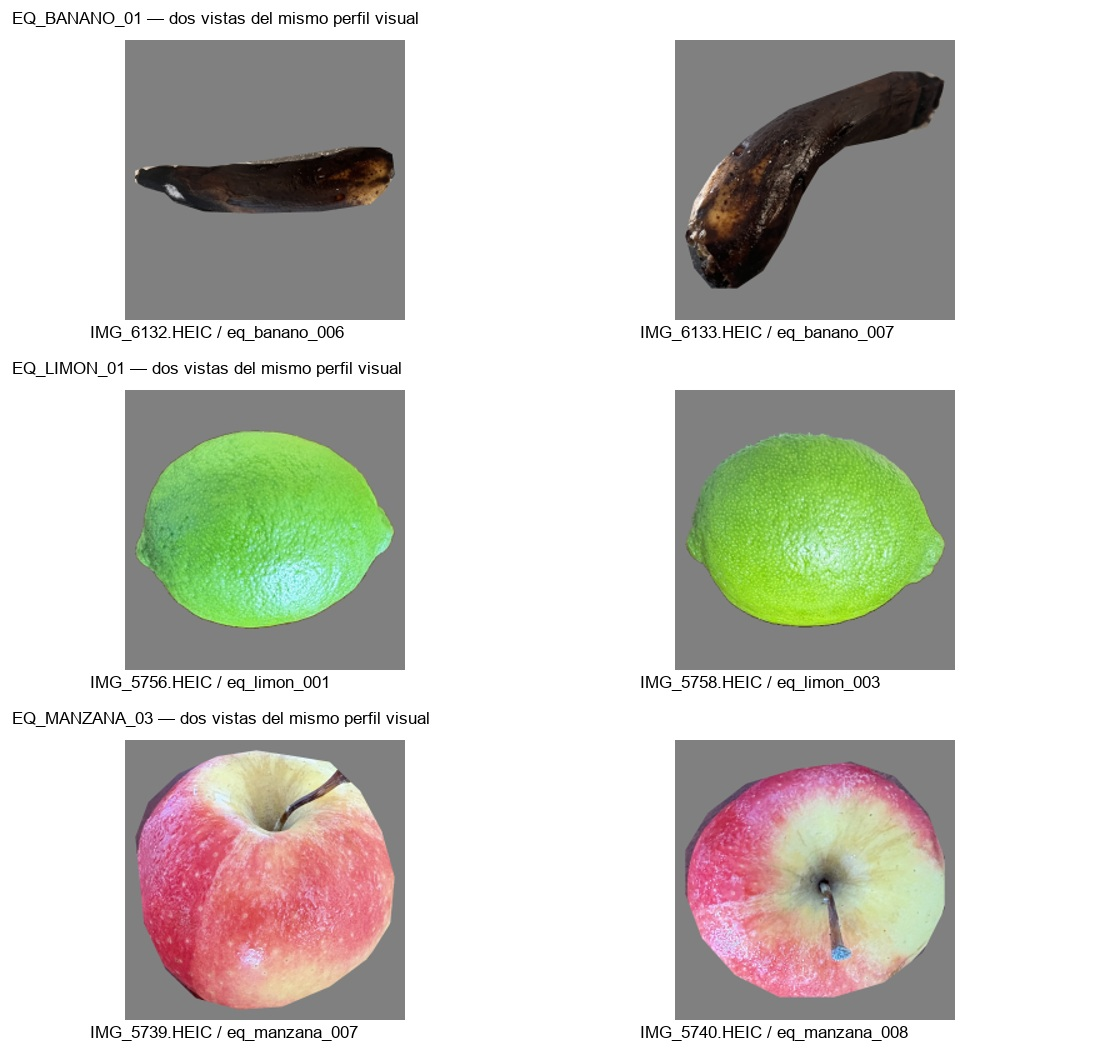

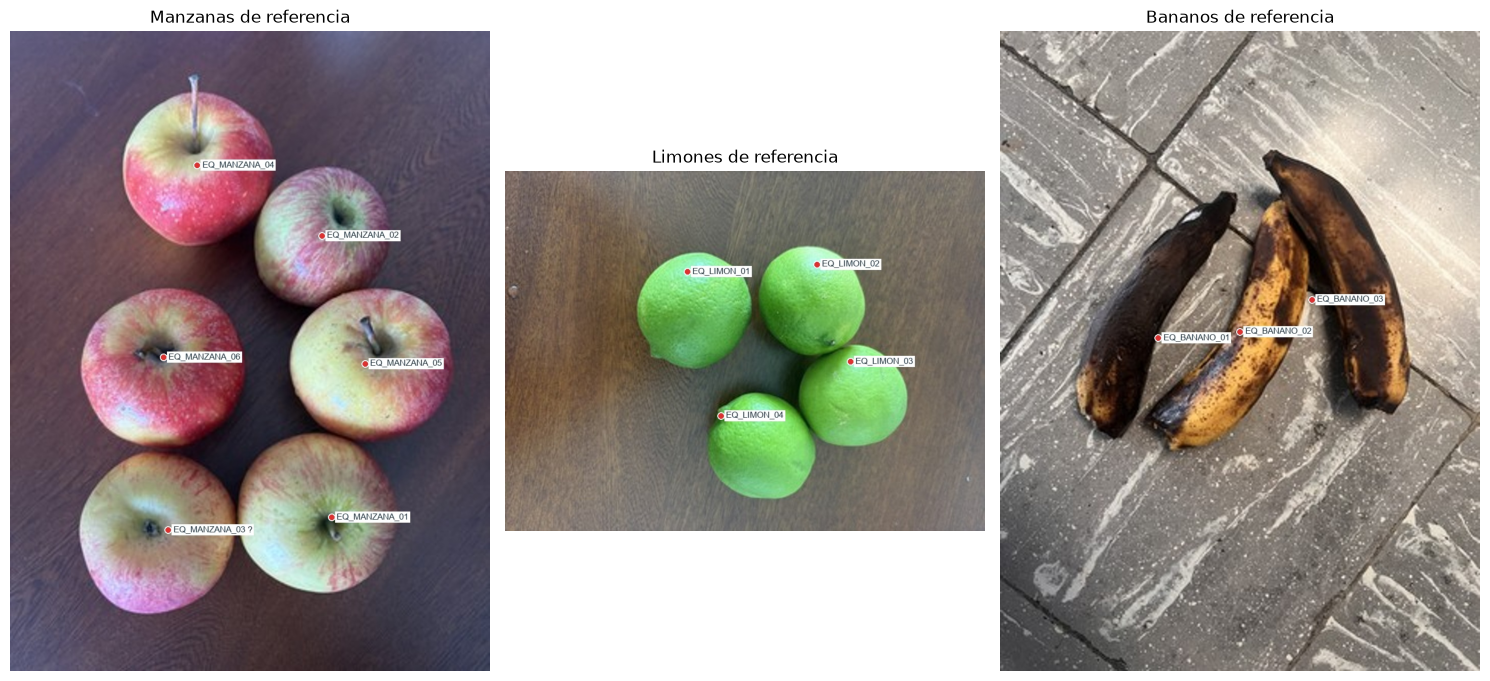

In [ ]:
EVIDENCIA=PROYECTO/'experiments/results/identidad_propias'
display(Image.open(EVIDENCIA/'vistas_repetidas.jpg'))
fig,ejes=plt.subplots(1,3,figsize=(15,7))
for eje,archivo,titulo in zip(ejes,
    ['eq_manzana_016_identificado.jpg','eq_limon_008_identificado.jpg','eq_banano_001_identificado.jpg'],
    ['Manzanas de referencia','Limones de referencia','Bananos de referencia']):
    with Image.open(EVIDENCIA/archivo) as im:eje.imshow(im)
    eje.axis('off');eje.set_title(titulo)
plt.tight_layout();plt.show()

## 3. Tabla por fotografía e incertidumbres

El identificador individual queda vacío cuando aparecen varios frutos o cuando
la identidad no se puede resolver. La tabla de ocurrencias conserva cada región.
El usuario confirmó que IMG_6120 e IMG_6121 son el mismo fruto: EQ_MANZANA_07.
Se retiró la alternativa 09; el perfil 09 aparece como otro fruto en fotos de grupo.

En limones hay dudas entre las vistas de grupo y las caras sanas/dañadas, por lo
que se conserva un bloque de evaluación común. La foto del plato IMG_6138 sigue
sin identidad resuelta y permanece excluida del entrenamiento.


In [ ]:
display(fotos[['codigo_revision','nombre_original','id_fruto_propuesto','ids_frutos_visibles',
    'certeza_identidad','ids_alternativos','grupo_evaluacion_seguro']])
pendientes=pd.read_csv(PROYECTO/'data/annotations/identidad_propias/correspondencias_por_confirmar.csv',keep_default_na=False)
display(pendientes[['codigo_revision','nombre_original','ids_frutos_visibles','ids_alternativos','estado_identidad']])

,codigo_revision,nombre_original,id_fruto_propuesto,ids_frutos_visibles,certeza_identidad,ids_alternativos,grupo_evaluacion_seguro
0,eq_banano_001,IMG_6127.HEIC,,EQ_BANANO_01|EQ_BANANO_02|EQ_BANANO_03,varias_regiones,,
1,eq_banano_002,IMG_6128.HEIC,,EQ_BANANO_01|EQ_BANANO_02|EQ_BANANO_03,varias_regiones,,
2,eq_banano_003,IMG_6129.HEIC,,EQ_BANANO_01|EQ_BANANO_02|EQ_BANANO_03,varias_regiones,,
3,eq_banano_004,IMG_6130.HEIC,,EQ_BANANO_01|EQ_BANANO_02|EQ_BANANO_03,varias_regiones,,
4,eq_banano_005,IMG_6131.HEIC,,EQ_BANANO_03|EQ_BANANO_02|EQ_BANANO_01,varias_regiones,,
5,eq_banano_006,IMG_6132.HEIC,EQ_BANANO_01,EQ_BANANO_01,alta,,propia_EQ_BANANO_01
6,eq_banano_007,IMG_6133.HEIC,EQ_BANANO_01,EQ_BANANO_01,alta,,propia_EQ_BANANO_01
7,eq_banano_008,IMG_6134.HEIC,,EQ_BANANO_01|EQ_BANANO_02,varias_regiones,,
8,eq_banano_009,IMG_6135.HEIC,,EQ_BANANO_01|EQ_BANANO_02,varias_regiones,,
9,eq_banano_010,IMG_6136.HEIC,,EQ_BANANO_02|EQ_BANANO_03|EQ_BANANO_01,varias_regiones,,


,codigo_revision,nombre_original,ids_frutos_visibles,ids_alternativos,estado_identidad
0,eq_banano_012,IMG_6138.HEIC,,EQ_BANANO_01|EQ_BANANO_02|EQ_BANANO_03,sin_resolver
1,eq_limon_004,IMG_5759.HEIC,EQ_LIMON_01|EQ_LIMON_02,EQ_LIMON_03|EQ_LIMON_04,varios_frutos
2,eq_limon_005,IMG_5760.HEIC,EQ_LIMON_01|EQ_LIMON_02,EQ_LIMON_03|EQ_LIMON_04,varios_frutos
3,eq_limon_006,IMG_5761.HEIC,EQ_LIMON_01|EQ_LIMON_04,EQ_LIMON_03|EQ_LIMON_04,varios_frutos
4,eq_limon_007,IMG_5762.HEIC,EQ_LIMON_03|EQ_LIMON_02,EQ_LIMON_04,varios_frutos
5,eq_limon_013,IMG_5754.HEIC,EQ_LIMON_06,EQ_LIMON_05,propuesta_visual


## 4. Corregir una identidad individual

Elegir la foto y un perfil de la misma fruta. Registrar nombre y evidencia antes
de guardar. Las alternativas inciertas unen bloques de evaluación para evitar
separar vistas posiblemente repetidas. Una corrección no libera automáticamente
un bloque antiguo: esa separación requiere revisar sus vínculos. Después de
guardar, volver a ejecutar la exportación de la sección siguiente.

In [ ]:
import ipywidgets as widgets

inventario=pd.read_csv(PROYECTO/'data/annotations/drive_20261124/inventario_drive.csv',keep_default_na=False).set_index('codigo_revision')
individuales=fotos.loc[fotos.id_fruto_propuesto.ne('')].copy()
selector=widgets.Dropdown(options=[(f'{r.nombre_original} / {r.codigo_revision}',r.codigo_revision) for r in individuales.itertuples()],description='Foto:')
identificador=widgets.Dropdown(description='Identidad:')
alternativas=widgets.SelectMultiple(description='Alternativas:')
certeza=widgets.Dropdown(options=['alta','media'],description='Certeza:')
revisor=widgets.Text(description='Tu nombre:',value='')
notas=widgets.Textarea(description='Evidencia:',layout=widgets.Layout(width='95%',height='90px'))
guardar=widgets.Button(description='Guardar identidad',button_style='success')
salida=widgets.Output()

def mostrar_identidad(change=None):
    manifest,perfiles,apariciones,actuales=cargar_identidades(PROYECTO)
    code=selector.value;fila=actuales.set_index('codigo_revision').loc[code]
    ids=perfiles.loc[perfiles.fruta.eq(fila.fruta),'id_fruto'].tolist()
    identificador.options=ids;alternativas.options=ids
    identificador.value=fila.id_fruto_propuesto
    alternativas.value=tuple(v for v in fila.ids_alternativos.split('|') if v)
    registro=apariciones.loc[apariciones.codigo_revision.eq(code)].iloc[0]
    certeza.value=registro.certeza_visual;notas.value=registro.evidencia;revisor.value=''
    with salida:
        clear_output(wait=True)
        with Image.open(inventario.loc[code,'ruta_miniatura']) as im:display(im.copy())
        print('Propuesta:',fila.id_fruto_propuesto,'| Bloque seguro:',fila.grupo_evaluacion_seguro)

def guardar_desde_editor(button):
    try:
        guardar_identidad_individual(PROYECTO,selector.value,identificador.value,list(alternativas.value),
            certeza.value,notas.value,revisor.value)
    except ValueError as error:
        with salida:print('No se guardó:',error)
    else:
        with salida:print('Guardado con historial. Volver a ejecutar la exportación de la sección 5.')

selector.observe(mostrar_identidad,names='value');guardar.on_click(guardar_desde_editor)
display(widgets.VBox([selector,identificador,alternativas,certeza,revisor,notas,guardar,salida]))
mostrar_identidad()

## 5. Aplicar las identidades a la base preparada

Se conserva el conjunto de 291 ejemplos y sus 43 características. Solo se añaden
metadatos de identidad y se actualizan los grupos propios seguros. Las fuentes
públicas mantienen sus agrupaciones conservadoras. Un identificador propuesto
puede compartir grupo con otro cuando no se sabe si son el mismo fruto.

In [ ]:
base,resumen,estado=exportar(PROYECTO)
propias=base.loc[base.fuente.eq('propia')].copy()
print('Base:',len(base),'| Fotos propias utilizadas:',len(propias))
print('Identidades propuestas en fotos propias de la base:',propias.id_fruto_propuesto.nunique())
print('Grupos seguros propios:',propias.grupo_particion.nunique(),'| Grupos de toda la base:',estado['grupos_conservadores'])
assert len(base)==291 and len(propias)==25
assert propias.id_fruto_propuesto.ne('').all()
assert propias.groupby('id_fruto_propuesto').grupo_particion.nunique().eq(1).all()
assert not set(['id_fruto_propuesto','certeza_identidad','revisor_identidad','grupo_particion'])&set(estado['caracteristicas'])
display(propias[['codigo_revision','id_fruto_propuesto','certeza_identidad','grupo_ejemplar','calidad_revisada']])
display(propias.groupby(['fruta','calidad_revisada']).agg(
    fotografias=('id_ejemplar','size'),identidades_propuestas=('id_fruto_propuesto','nunique'),
    grupos_seguros=('grupo_particion','nunique')).reset_index())

Base: 291 | Fotos propias utilizadas: 25
Identidades propuestas en fotos propias de la base: 12
Grupos seguros propios: 10 | Grupos de toda la base: 22


,codigo_revision,id_fruto_propuesto,certeza_identidad,grupo_ejemplar,calidad_revisada
21,eq_banano_006,EQ_BANANO_01,alta,propia_EQ_BANANO_01,mala
22,eq_banano_007,EQ_BANANO_01,alta,propia_EQ_BANANO_01,mala
23,eq_limon_001,EQ_LIMON_01,alta,propia_limon_bloque_correspondencias_inciertas,buena
24,eq_limon_003,EQ_LIMON_01,alta,propia_limon_bloque_correspondencias_inciertas,buena
25,eq_limon_010,EQ_LIMON_05,alta,propia_limon_bloque_correspondencias_inciertas,intermedia
26,eq_limon_011,EQ_LIMON_06,alta,propia_limon_bloque_correspondencias_inciertas,mala
27,eq_limon_012,EQ_LIMON_05,alta,propia_limon_bloque_correspondencias_inciertas,intermedia
28,eq_limon_013,EQ_LIMON_06,media,propia_limon_bloque_correspondencias_inciertas,mala
29,eq_limon_014,EQ_LIMON_06,alta,propia_limon_bloque_correspondencias_inciertas,mala
30,eq_manzana_001,EQ_MANZANA_01,alta,propia_EQ_MANZANA_01,buena


,fruta,calidad_revisada,fotografias,identidades_propuestas,grupos_seguros
0,banano,mala,2,1,1
1,limon,buena,2,1,1
2,limon,intermedia,2,1,1
3,limon,mala,3,1,1
4,manzana,buena,13,6,6
5,manzana,mala,3,2,2


## 6. Preparación de la comparación

Ya pueden usarse los grupos seguros al diseñar una validación agrupada. Las
identidades que aparecen en una partición deberán quedar completas en ella; los
bloques de incertidumbre y los vínculos de origen/archivo también se respetan.
La confirmación del usuario separa las dos fechas de manzanas, pero no aumenta
automáticamente la independencia de los limones ni de las fuentes públicas.

Todavía hay pocas unidades independientes en categorías como limón intermedio y
malo. El lote ya se utilizó para desarrollar el procesamiento y no se convierte
retroactivamente en prueba independiente. Este cuaderno no compara modelos ni
publica métricas de generalización. El cuaderno 04 conserva el ajuste técnico de referencia.